# Distribution Shape

*Interpret skewness and kurtosis with explicit formulas, conventions, and observed distributions.*


## Standardized Moments Summarize Shape

For this descriptive calculation, define $m_k=\frac{1}{n}\sum_i(x_i-\bar{x})^k$.
Skewness is $g_1=m_3/m_2^{3/2}$ and Pearson kurtosis is $b_2=m_4/m_2^2$.
Both are dimensionless and require positive variance.

Skewness uses a signed third power, so values far on the right contribute
positively and values far on the left contribute negatively. Zero skewness
does not prove symmetry. A normal population has Pearson kurtosis 3;
**excess kurtosis** subtracts 3 and therefore has a normal reference of 0.
Kurtosis is sensitive to extreme standardized deviations and is not simply
a measure of the height of a distribution's central peak.


## State Which Estimator Is Being Used

The formula below averages standardized third and fourth powers using
`ddof=0`. SciPy's `bias=True` matches these unadjusted moment calculations.
Other functions can use sample-size corrections and therefore return different
numbers. A constant array receives undefined shape statistics.


In [1]:
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis


def describe_shape(values):
    values = np.asarray(values, dtype=float)
    scale = values.std(ddof=0)
    if scale == 0:
        return np.nan, np.nan, np.nan
    standardized = (values - values.mean()) / scale
    skewness = np.mean(standardized**3)
    pearson_kurtosis = np.mean(standardized**4)
    return skewness, pearson_kurtosis, pearson_kurtosis - 3


right_tail = np.array([1, 2, 2, 3, 3, 4, 4, 5, 6, 15], dtype=float)
shape_values = describe_shape(right_tail)
print("Skewness, Pearson kurtosis, excess kurtosis:", np.round(shape_values, 4))
print("SciPy skewness:", round(skew(right_tail, bias=True), 4))
print(
    "SciPy Pearson kurtosis:", round(kurtosis(right_tail, fisher=False, bias=True), 4)
)
print("Constant-data shape:", describe_shape([3, 3, 3]))


Skewness, Pearson kurtosis, excess kurtosis: [2.0077 6.1058 3.1058]
SciPy skewness: 2.0077
SciPy Pearson kurtosis: 6.1058
Constant-data shape: (nan, nan, nan)


The right-tailed sample has skewness about 2.0077, Pearson kurtosis 6.1058,
and excess kurtosis 3.1058. The two kurtosis values differ by exactly 3.
The constant sample has undefined shape statistics, represented by NaN.


## Compare Mirrored and Symmetric Samples

Reflecting values through zero reverses the sign of skewness. It leaves
fourth-power kurtosis unchanged. A histogram shows which actual observations
produce the summary. Use the same bin edges and axis limits for the three
views so the comparison has a shared scale.


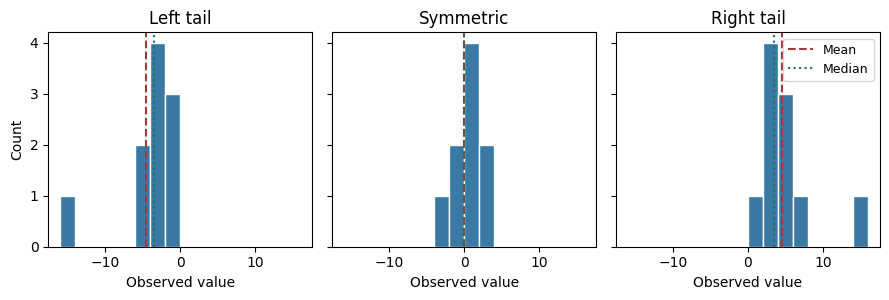

    sample  mean  median  skewness  excess_kurtosis
 Left tail  -4.5    -3.5   -2.0077           3.1058
 Symmetric   0.0     0.0    0.0000          -0.7500
Right tail   4.5     3.5    2.0077           3.1058


In [2]:
import matplotlib.pyplot as plt

samples = {
    "Left tail": -right_tail,
    "Symmetric": np.array([-3, -2, -1, 0, 0, 0, 1, 2, 3], dtype=float),
    "Right tail": right_tail,
}
shape_rows = []
fig, axes = plt.subplots(1, 3, figsize=(9.0, 3.1), dpi=100, sharex=True, sharey=True)
for ax, (name, values) in zip(axes, samples.items()):
    skewness, pearson_kurtosis, excess_kurtosis = describe_shape(values)
    shape_rows.append(
        {
            "sample": name,
            "mean": values.mean(),
            "median": np.median(values),
            "skewness": skewness,
            "excess_kurtosis": excess_kurtosis,
        }
    )
    ax.hist(values, bins=np.arange(-16, 18, 2), color="#3979a3", edgecolor="white")
    ax.axvline(values.mean(), color="#a33939", linestyle="--", label="Mean")
    ax.axvline(np.median(values), color="#23744b", linestyle=":", label="Median")
    ax.set_title(name, fontsize=12)
    ax.set_xlabel("Observed value")
axes[0].set_ylabel("Count")
axes[-1].legend(fontsize=9)
fig.tight_layout()
plt.show()
plt.close(fig)
print(pd.DataFrame(shape_rows).round(4).to_string(index=False))


The mirrored samples have skewness of opposite sign and equal excess
kurtosis. The right-tailed sample has mean 4.5 and median 3.5; the left-tailed
sample has mean -4.5 and median -3.5. The symmetric sample has zero mean,
median, and skewness, but its excess kurtosis is -0.75, not the normal value 0.
Mean–median ordering is a useful clue here, not a universal test of shape.


## Shape Statistics Do Not Identify a Distribution

A kurtosis value of 3 does not prove normality, and a large value does not by
itself prove measurement error. Small samples can yield unstable shape
estimates. Read these numbers together with the observations, a plot, and the
way the data were collected.

[SciPy kurtosis conventions](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.kurtosis.html).


Name the kurtosis convention and any estimator correction. Skewness and kurtosis summarize different aspects of shape and should be interpreted alongside a plot.

[Related explanation in the source lecture](https://www.youtube.com/watch?v=9bM65kxOwPA&t=5022s).
